# Random Forest

Many decision trees (notebook 03), each trained on a random sample of the rows and choosing each split from a random subset of features. The forest predicts by majority vote, which smooths out the mistakes of individual trees.

Two versions in `src/models.py`:

- `random_forest()`: 300 trees, default settings, plus an out-of-bag (OOB) accuracy estimate computed from the rows each tree skipped.
- `random_forest_tuned()`: keeps only the top 5 features by forest importance and uses shallower, regularised trees. Tuned to catch DoS types it was never trained on (see `docs/random_forest_notes.md` §11). Works best given all 41 features so it can choose its own.

The deeper analysis (feature-importance verification, tuning search) lives in `notebooks/random_forest_analysis/` and is written up in `docs/random_forest_notes.md`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from dosdetect.models import MODELS
from dosdetect.paths import RF_RESULTS_DIR
from dosdetect.report import metrics_table, plot_confusion, run
from dosdetect.run import prepare

pd.set_option("display.precision", 4)

## Data

NSL-KDD, normal and DoS traffic only. Two test setups:

- **official**: train on `KDDTrain+`, test on `KDDTest+`. About 23% of the test DoS rows are attack types the model never saw in training (apache2, mailbomb, processtable, udpstorm).
- **holdout**: a stratified 80/20 split of `KDDTrain+`, so every test attack type was also seen in training.

The paper keeps the 8 features most correlated with the label. We also try all 41.

In [2]:
data = {
    (split, n): prepare(split, n_features=n) for split in ("official", "holdout") for n in (8, 41)
}
official = data[("official", 8)]
print("Train rows:", len(official["X_train"]), " Test rows:", len(official["X_test"]))
print("Unseen DoS rows in official test:", official["unseen"].sum())
official["prep"].correlations.head(8).rename("|correlation| with label").to_frame()

Train rows: 113270  Test rows: 17169
Unseen DoS rows in official test: 1717


,|correlation| with label
same_srv_rate,0.8654
dst_host_srv_serror_rate,0.7913
dst_host_serror_rate,0.7855
srv_serror_rate,0.7853
serror_rate,0.7850
dst_host_same_srv_rate,0.7600
flag,0.7567
dst_host_srv_count,0.7189


## Results

Same model, all four setups. `recall_unseen` is the share of never-seen DoS attack types the model still catches (official split only).

In [3]:
results, matrices = {}, {}
for (split, n), d in data.items():
    r = run(MODELS["random_forest"](), d)
    matrices[(split, n)] = r.pop("confusion_matrix")
    results[f"{split}, {n} features"] = r
metrics_table(results)

,accuracy,precision,recall,f1,recall_seen,recall_unseen,train_time_s,predict_time_s
"official, 8 features",0.8461,0.9785,0.6602,0.7885,0.8140,0.1462,8.5499,0.3363
"official, 41 features",0.9027,0.9859,0.7873,0.8755,0.9962,0.0891,9.7099,0.1898
"holdout, 8 features",0.9604,0.9834,0.9179,0.9495,NaN,NaN,3.0413,0.2052
"holdout, 41 features",0.9999,0.9999,0.9998,0.9998,NaN,NaN,3.5976,0.1745


### Confusion matrices

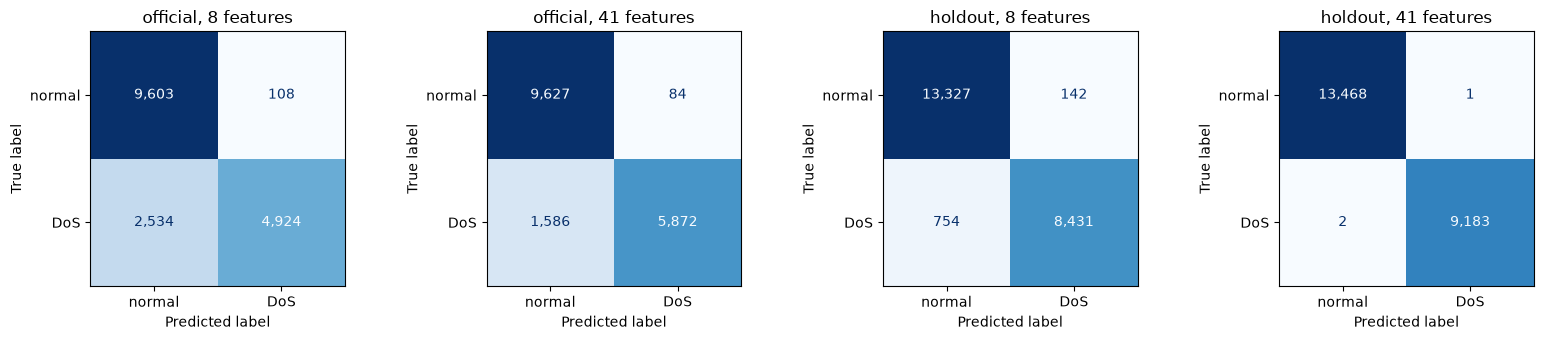

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, (key, cm) in zip(axes, matrices.items(), strict=True):
    plot_confusion(cm, f"{key[0]}, {key[1]} features", ax=ax)
plt.tight_layout()

## Tuned Random Forest

Same four setups with the tuned version.

In [5]:
tuned = {}
for (split, n), d in data.items():
    r = run(MODELS["random_forest_tuned"](), d)
    r.pop("confusion_matrix")
    tuned[f"{split}, {n} features"] = r
pd.concat({"default": metrics_table(results), "tuned": metrics_table(tuned)})[
    ["accuracy", "precision", "recall", "f1", "recall_unseen"]
]

accuracy  precision  recall      f1  \
default official, 8 features     0.8461     0.9785  0.6602  0.7885   
        official, 41 features    0.9027     0.9859  0.7873  0.8755   
        holdout, 8 features      0.9604     0.9834  0.9179  0.9495   
        holdout, 41 features     0.9999     0.9999  0.9998  0.9998   
tuned   official, 8 features     0.8636     0.9906  0.6925  0.8152   
        official, 41 features    0.9059     0.9893  0.7920  0.8797   
        holdout, 8 features      0.9598     0.9894  0.9107  0.9484   
        holdout, 41 features     0.9969     0.9928  0.9997  0.9962   

                               recall_unseen  
default official, 8 features          0.1462  
        official, 41 features         0.0891  
        holdout, 8 features              NaN  
        holdout, 41 features             NaN  
tuned   official, 8 features          0.2737  
        official, 41 features         0.2697  
        holdout, 8 features              NaN  
        holdout, 41 features             NaN

## Feature importance

Produced by `experiments/random_forest/feature_importance.py`. Built-in importance (MDI, from training) next to permutation importance (F1 drop on the test set when one feature is shuffled).

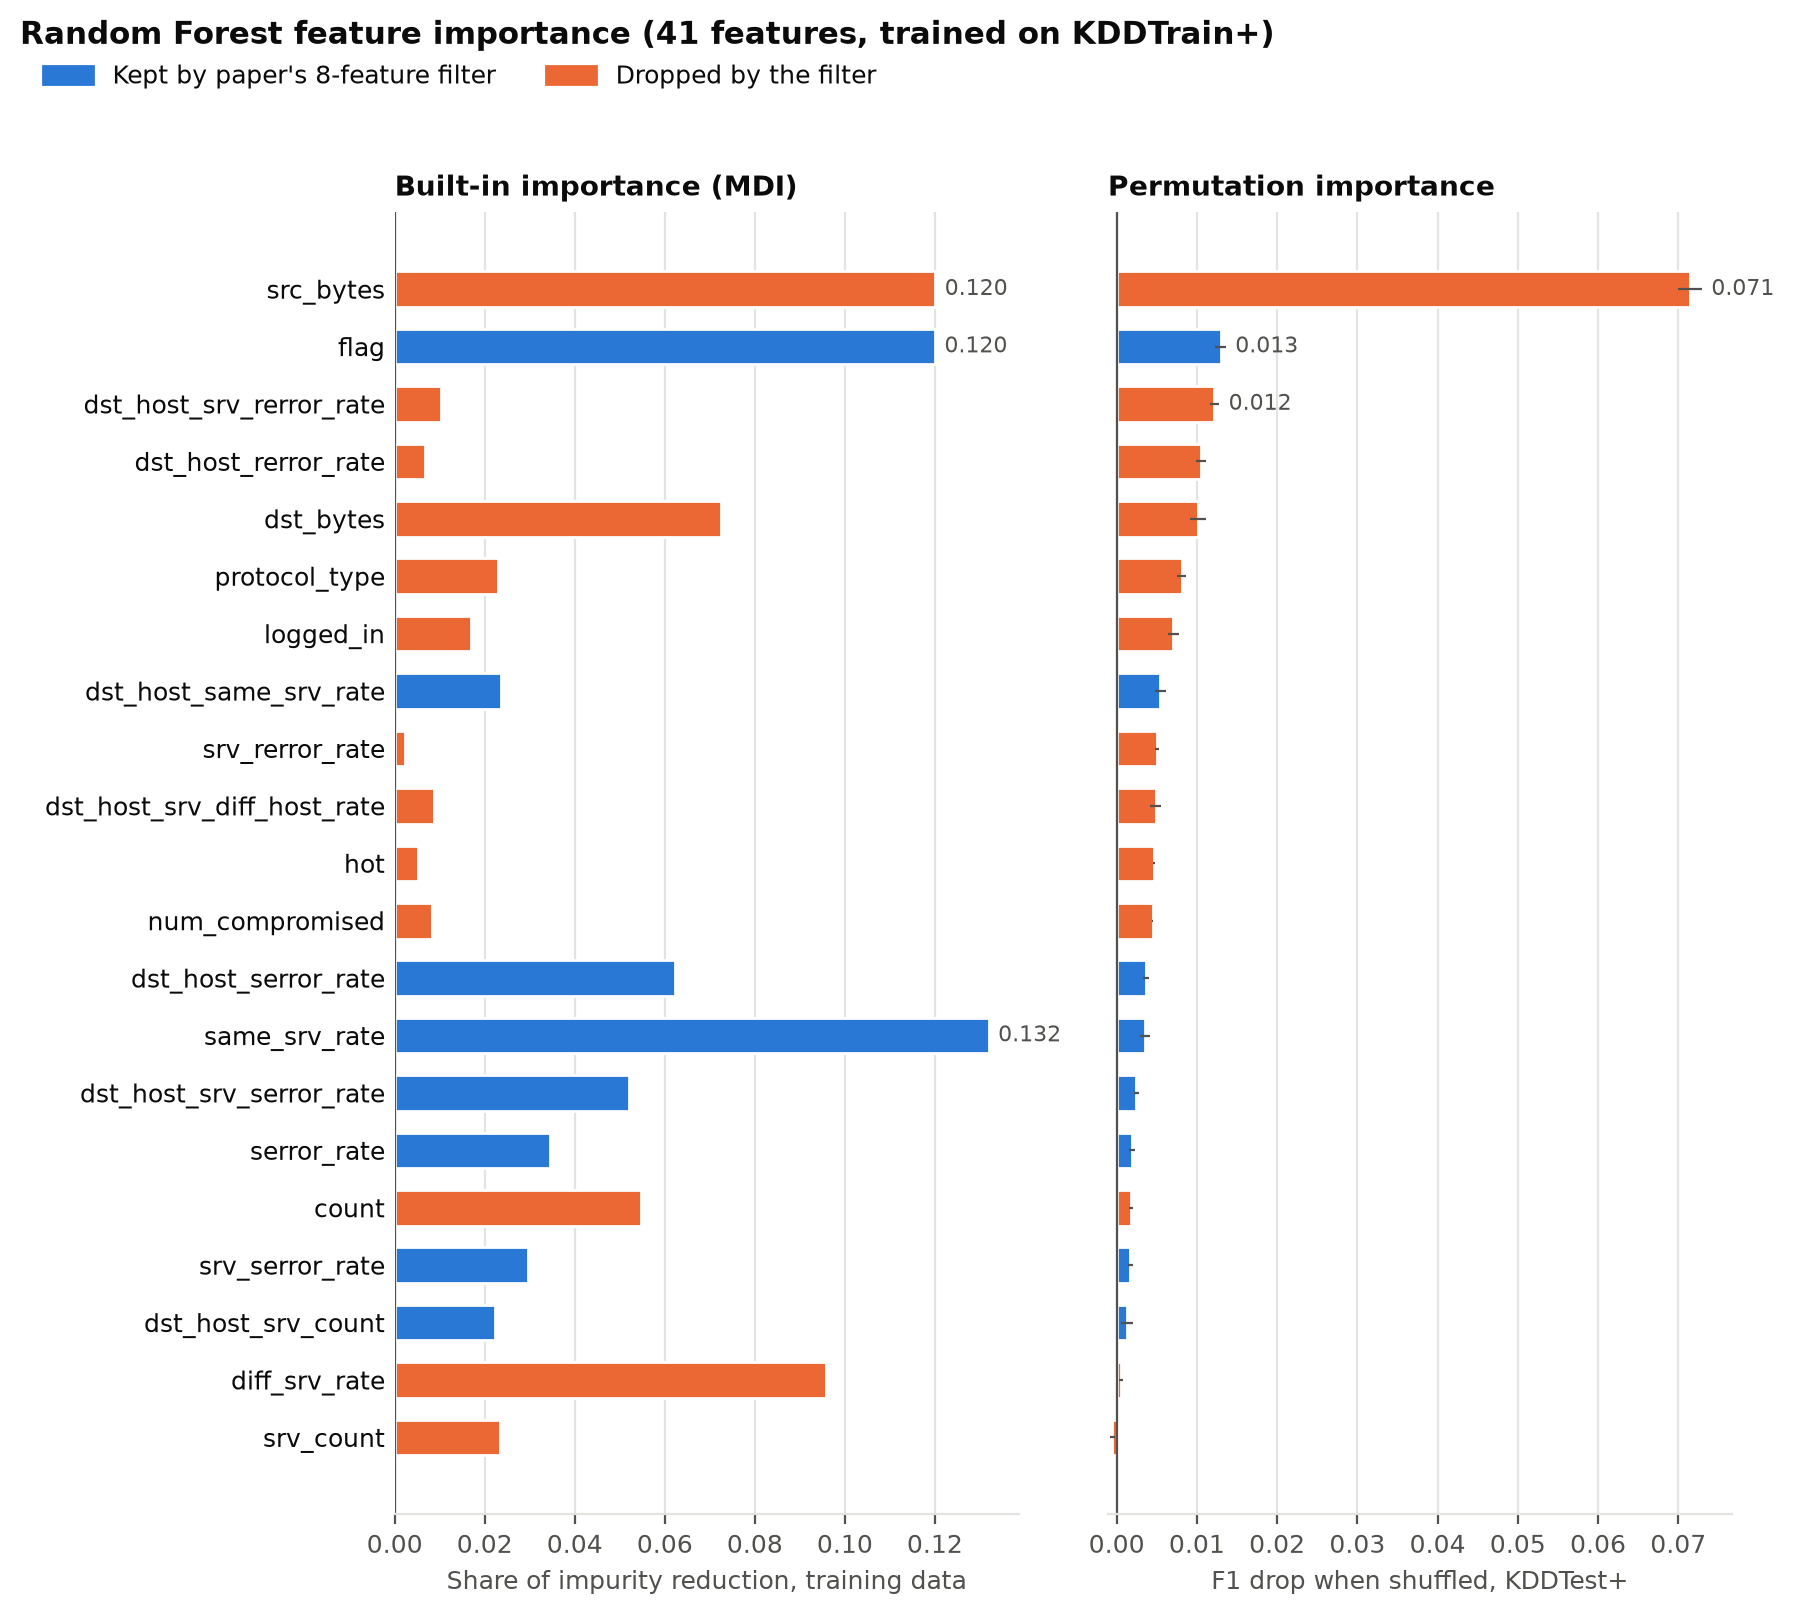

In [6]:
from IPython.display import Image

Image(RF_RESULTS_DIR / "feature_importance.png")

## Takeaways

- **On the official file, averaging 300 trees barely beats one tree.** The default forest scores 90.3% accuracy with 41 features versus 90.5% for the single decision tree. On the holdout split it is near-perfect (99.99%), but so is the tree.
- **The default forest is worst at new attack types**: 9–15% recall on never-seen DoS types. It fits known attacks very tightly, and its out-of-bag score (~0.96 with 8 features, ~1.00 with 41) reflects only those.
- **Tuning helps where it was aimed.** The tuned forest roughly doubles unseen-type recall (to about 27%) and has the best official accuracy (90.6%, 41 features), at a small cost on the holdout split (99.7% vs 99.99%).
- **Feature importance** (41 features) disagrees with the paper's filter. The forest relies most on `src_bytes` (bytes sent by the source) and `flag`. `src_bytes` has almost no linear correlation with the label (0.02), so the paper's 8-feature filter drops it. Adding it back to the paper's 8 raises F1 from 0.79 to 0.88 (`docs/random_forest_notes.md` §10).